# 2026F - San Jose State University - CMPE-257 - project - Chris Carl

## Metadata
<div style="display: inline-block">
<!-- get the table rendered to the left rather than default center, the spaces after the raw html are important for markdown https://stackoverflow.com/a/78525025 -->

| Key | Value |
| :--- | :--- |
| author | Chris Carl(mailto:chris.carl@sjsu.edu) |
| date | 2026-11-13 |
| dataset | [AmesHousing.txt, save as CSV](https://jse.amstat.org/v19n3/decock/AmesHousing.txt) © 2015 American Statistical Association |

<!-- get the table rendered to the left rather than default center, the spaces after the raw html are important for markdown https://stackoverflow.com/a/78525025 -->
</div>

<!--
commands:
    ipynb CMPE-257/assignments/project/project.ipynb  # chriscarl.tools.documents
-->


# Abstract

This is my submission of project of CMPE-257 at SJSU instructed by Dr. Zara Hajihashemi in Fall 2026.

Explain the executive summary and findings. You HAVE TO. this is the first thing they see.


# TOC


<!-- # SUGGESTED TOC ORGANIZATION

# Project
# Abstract
# Table of Contents
# Question
# Answer
# Solution
## Background
## The Plan
## Code - Environment
## Code - Setup
## Code - Functions
## Code - Main
# Post Mortem
## Caveats
## Improvements
## Replication
# Appendix
## Criterion
## Changelog
-->

# Solution


## Code - Setup

The following is boilerplate I've accumulated over the years and can be safely disregarded by the reader until it becomes relevant as part of deeper inquiry.


In [1]:
# stdlib imports
import __main__
import os
import sys
import pprint
import importlib
import subprocess
# hyper-critical imports
try:
    from IPython import get_ipython
    IPYTHON_SHELL = get_ipython()  # None if running in vanilla python
except ImportError:
    IPYTHON_SHELL = None

SCRIPT_FILEPATH = ''
SCRIPT_FILENAME = ''
if IPYTHON_SHELL:
    SCRIPT_DIRPATH = str(IPYTHON_SHELL.run_line_magic('pwd', ' # %pwd is a "magic" command  https://ipython.readthedocs.io/en/stable/interactive/magics.html'))
    if hasattr(__main__, '__vsc_ipynb_file__'):  # vscode
        SCRIPT_FILEPATH = __main__.__vsc_ipynb_file__
    elif hasattr(__main__, '__session__'):  # localhost:8888/notebooks
        SCRIPT_FILEPATH = __main__.__session__
else:
    SCRIPT_FILEPATH = __file__
    SCRIPT_DIRPATH = os.path.dirname(SCRIPT_FILEPATH)

SCRIPT_FILENAME = os.path.splitext(os.path.basename(SCRIPT_FILEPATH))[0]

pprint.pprint(dict(dir=SCRIPT_DIRPATH, fp=SCRIPT_FILEPATH, fn=SCRIPT_FILENAME), indent=2)

AUTO_INSTALL = False
packages = {}  # {'Werkzeug': 'werkzeug'}  # package name: module name
modules = ['matplotlib', 'pandas', 'ipykernel', 'ipympl', 'ipywidgets']
packages.update({m: m for m in modules})
package, module = '', ''
install_string = ' '.join(packages)
try:
    for package, module in packages.items():
        importlib.import_module(module)
except ImportError:
    print(f'"pip install {package}"', file=sys.stderr)
    if AUTO_INSTALL:
        %pip install {install_string}
    else:
        raise

# third party imports
import matplotlib.pyplot as plt

EXES = {
    'pandoc': {'exists': False},
    'latex': {'exists': False, 'win32': 'miktex', 'linux': 'texlive'},
}

for exe, data in EXES.items():
    if IPYTHON_SHELL:
        if sys.platform == 'win32':
            _res = !where.exe {exe}
            _exists = not _res[0].startswith('INFO')
        else:
            _res = !which {exe}
            _exists = bool(_res)
    else:
        if sys.platform == 'win32':
            _res = subprocess.check_output(f'where.exe {exe}', universal_newlines=True)
            _exists = not _res.startswith('INFO')
        else:
            _res = subprocess.check_output(f'which {exe}', universal_newlines=True)
            _exists = bool(_res)
    EXES[exe]['exists'] = _exists

print('pandoc:', EXES['pandoc']['exists'])
if not EXES['pandoc']['exists']:
    print('you must install pandoc!', file=sys.stderr)
    if sys.platform == 'win32':
        print('    choco install pandoc -y', file=sys.stderr)
    else:
        print('    sudo apt install pandoc -y', file=sys.stderr)
        print('    sudo yum install pandoc -y', file=sys.stderr)
        print('    dnf install pandoc -y', file=sys.stderr)
    raise RuntimeError()

print('latex:', EXES['latex']['exists'])
plt.rcParams.update(
    {
        'text.usetex': EXES['latex']['exists'],  # , 'font.family': 'Helvetica'  # requires latex installed
        'text.latex.preamble': r'\usepackage{amsmath}',  # https://stackoverflow.com/a/23856968  \text command
    }

)

# command to tell the notebook to plt.show() IN THE NOTEBOOK, otherwise you call plt.show()
%matplotlib inline
# command to tell the notebook to render interactable matplotlib, requires pip install ipympl
# %matplotlib widget

print('# pip install', install_string)
if not IPYTHON_SHELL:
    raise RuntimeError('Not sure how, but somehow this code is being run through a non-iPython environment!')


{ 'dir': 'c:\\Users\\chris\\src\\sjsu.CMPE-257.ml-social-bot-detection\\src',
  'fn': 'project',
  'fp': 'c:\\Users\\chris\\src\\sjsu.CMPE-257.ml-social-bot-detection\\src\\project.ipynb'}
pandoc: True
latex: True
# pip install matplotlib pandas ipykernel ipympl ipywidgets


# Setup

In [2]:
PROJECT_DIRECTORY = os.path.abspath(os.path.join(SCRIPT_DIRPATH, '..'))
DATASET_DIRECTORIES = [
    os.path.join(PROJECT_DIRECTORY, r'ignoreme\data\cresci-17'),
    os.path.join(PROJECT_DIRECTORY, r'ignoreme\data\twibot-22'),
]
RANDOM_STATE = 42

In [3]:
import os
import zipfile

def unzip_file(zip_path, extract_to, password=None, print_progress=True):
    if not os.path.isfile(zip_path):
        raise FileNotFoundError(f"ZIP file not found: {zip_path}")
    os.makedirs(extract_to, exist_ok=True)
    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            pwd = password.encode() if password else None
            for member in zip_ref.infolist():
                # Prevent Zip Slip vulnerability
                extracted_path = os.path.join(extract_to, member.filename)
                if member.filename.startswith('__MACOSX/._') or member.filename.split('/')[-1].startswith('._'):
                    continue

                if not os.path.realpath(extracted_path).startswith(os.path.realpath(extract_to)):
                    raise Exception(f"Unsafe file path detected: {member.filename}")

                if print_progress:
                    print(member)
                if not os.path.exists(extracted_path):
                    zip_ref.extract(member, path=extract_to, pwd=pwd)

                basename, ext = os.path.splitext(member.filename)

                if ext == '.zip':
                    unzip_file(os.path.join(extract_to, member.filename), os.path.join(extract_to, basename), password=password, print_progress=print_progress)
    except zipfile.BadZipFile:
        raise zipfile.BadZipFile(f"Invalid ZIP file: {zip_path}")
    except RuntimeError as e:
        if "password required" in str(e).lower():
            raise RuntimeError("This ZIP file is password-protected. Please provide a valid password.")
        else:
            raise


In [4]:
ZIPS = [
    os.path.join(PROJECT_DIRECTORY, r'ignoreme\data\cresci-17\datasets_full.csv.zip'),
]
for file in ZIPS:
    basename, _ = os.path.splitext(file)
    unzip_file(file, basename)


<ZipInfo filename='datasets_full.csv/' filemode='drwxr-xr-x' external_attr=0x10>
<ZipInfo filename='datasets_full.csv/crowdflower_results.csv.zip' compress_type=deflate filemode='-rw-r--r--' external_attr=0x4000 file_size=290528 compress_size=289584>
<ZipInfo filename='crowdflower_results.csv/' filemode='drwxr-xr-x' external_attr=0x4000>
<ZipInfo filename='crowdflower_results.csv/crowdflower_results_aggregated.csv' compress_type=deflate filemode='-rw-r--r--' external_attr=0x4000 file_size=617235 compress_size=107077>
<ZipInfo filename='__MACOSX/' filemode='drwxrwxr-x' external_attr=0x4000>
<ZipInfo filename='__MACOSX/crowdflower_results.csv/' filemode='drwxrwxr-x' external_attr=0x4000>
<ZipInfo filename='crowdflower_results.csv/crowdflower_results_contributors.csv' compress_type=deflate filemode='-rw-r--r--' external_attr=0x4000 file_size=24118 compress_size=8227>
<ZipInfo filename='crowdflower_results.csv/crowdflower_results_detailed.csv' compress_type=deflate filemode='-rw-r--r--' ex

In [5]:
import multiprocessing
import concurrent.futures
from typing import Callable, Any

MAX_WORKERS = multiprocessing.cpu_count() - 1

def parallel(funcs, args, kwargs, key=lambda args: args[0], max_workers=MAX_WORKERS):
    # type: (list[Callable], list[tuple], list[dict], Callable, int) -> list[tuple[Any, Any|Exception]]
    # https://docs.python.org/3/library/concurrent.futures.html
    N = len(funcs)
    if len(funcs) != len(args) or len(args) != len(kwargs):
        raise ValueError('need to provide same list amount of funcs, args, kwargs')

    res = []
    # NOTE: to run this, you need to use external files for the functions you have in mind
    with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
        future_to_ret = {executor.submit(funcs[i], *args[i], **kwargs[i]): key(args[i]) for i in range(len(args))}
        for f, future in enumerate(concurrent.futures.as_completed(future_to_ret)):
            arg = future_to_ret[future]
            try:
                data = future.result()
            except Exception as exc:
                print(f'{f+1} / {N} - FAILURE! {arg}: {exc}', file=sys.stderr)
                res += [(arg, exc)]
            else:
                print(f'{f+1} / {N} - SUCCESS! {arg}: {data}', file=sys.stdout)
                res += [(arg, data)]
    return res


In [6]:
%%writefile data_to_pickle.py
import os
import pickle
import warnings
import pandas as pd

def data_to_pickle(filepath, pickle_filepath, skip_exists=False):
    # type: (str, str) -> list[tuple[str, str]]
    changed_columns = []
    if not skip_exists and os.path.isfile(pickle_filepath) and os.path.getsize(filepath) / os.path.getsize(pickle_filepath) > 0.3:
        changed_columns += [('pickle', 'exists')]
        return changed_columns

    ext = os.path.splitext(filepath)[1]
    if ext.lower() == '.json':
        try:
            df = pd.read_json(filepath, dtype=str, encoding='utf-8', orient='records')
        except UnicodeDecodeError:
            df = pd.read_json(filepath, dtype=str, encoding='latin-1', orient='records')
    elif ext.lower() == '.csv':
        try:
            df = pd.read_csv(filepath, dtype=str, encoding='utf-8', low_memory=False)
        except UnicodeDecodeError:
            df = pd.read_csv(filepath, dtype=str, encoding='latin-1', low_memory=False)
    else:
        raise NotImplementedError(f'no parser implemented for {ext.lower()!r}')

    for col in df.columns:
        if df[col].nunique() < 69:
            df[col] = df[col].astype('category')
            changed_columns.append((col, 'category'))
            continue


        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            try:
                    df[col] = pd.to_numeric(df[col])
                    changed_columns.append((col, 'int/float'))
                    continue
            except Exception:
                pass

            try:
                    df[col] = pd.to_datetime(df[col])
                    changed_columns.append((col, 'datetime'))
                    continue  # useless, but keeps the pattern
            except Exception:
                pass

    with open(pickle_filepath, 'wb') as f:
        pickle.dump(df, f)

    return changed_columns

Overwriting data_to_pickle.py


In [7]:
import os
import glob
import pandas as pd
from data_to_pickle import data_to_pickle


funcs, args, kwargs = [], [], []
data_to_pickle_filepaths = {}
for d, dataset_directory in enumerate(DATASET_DIRECTORIES):
    globs = list(glob.glob(os.path.join(dataset_directory, '**', '*.csv'), recursive=True))
    globs += list(glob.glob(os.path.join(dataset_directory, '**', '*.json'), recursive=True))
    globs = sorted(globs, key=lambda pth: os.path.getsize(pth), reverse=True)  # complete in greatest to least
    for c, data_filepath in enumerate(globs):
        if not os.path.isfile(data_filepath):  # could be named datasets_full.csv...
            continue
        filename = os.path.splitext(data_filepath)[0]
        if os.path.getsize(data_filepath) > 4 * 1024 ** 3:  # > 4GB, not today, I dont need the hugest files
            continue

        pickle_filepath = f'{filename}.pkl'

        funcs += [data_to_pickle]
        args += [(data_filepath, pickle_filepath)]
        kwargs += [dict()]

        data_to_pickle_filepaths[data_filepath] = pickle_filepath

results = parallel(funcs, args, kwargs, key=lambda args: args[0], max_workers=6)

errors = []
original, pickled = 0, 0
for t, tpl in enumerate(results):
    data_filepath, result = tpl
    pickle_filepath = data_to_pickle_filepaths[data_filepath]
    print(f'{t+1} / {len(results)} - "{os.path.relpath(data_filepath, PROJECT_DIRECTORY)}"')
    if isinstance(result, Exception):
        errors.append(data_filepath)
    else:
        original += os.path.getsize(data_filepath)
        pickled += os.path.getsize(pickle_filepath)

print(f'saved {((original - pickled) / original * 100):0.3f}% from {original / 1024**3:0.3f}GB to {pickled / 1024**3:0.3f}GB')
for error in errors:
    print(f'  - "{error}"')


1 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme\data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_1.csv\social_spambots_1.csv\tweets.csv: [('pickle', 'exists')]
2 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme\data\cresci-17\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\users.csv: [('pickle', 'exists')]
3 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme\data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_3.csv\social_spambots_3.csv\tweets.csv: [('pickle', 'exists')]
4 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme\data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_2.csv\social_spambots_2.csv\tweets.csv: [('pickle', 'exists')]
5 / 24 - SUCCESS! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme\data\cresci-17\datasets_full.csv\datasets_full.csv\social_spamb

19 / 24 - FAILURE! c:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme\data\cresci-17\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\tweets.csv: Error tokenizing data. C error: Expected 26 fields in line 8, saw 27



"But no dataset can generalize well on all other datasets." - 1099
Basically, construct a random forest on one dataset, evaluate it on another dataset.

Basically, create an AUC table.
seperability - averaging across columns
generalizability - averaging across rows

They find no correlation between separability and generalizabilitty, r=0.18, p=0.6

AUC - area under ROC curve (plotting false positives as X vs true positives as Y), want close to 1.0

RandomForest 100 trees
5-fold CV

Chose a threshold, Different thresholds yield best ac-
curacy in cross-validation (F1 = 0 .94, R = 0 .93, P = 0 .94)
or cross-domain testing (F1 = 0 .77, R = 0 .68, P = 0 .88)

botometer is the baseline, Yang et al. 2019 - Yang, K.-C.; Varol, O.; Davis, C. A.; Ferrara, E.; Flammini, A.; and Menczer, F. 2019. Arming the public with artificial intelligence to counter social bots. Hum. Behav. and Emerg. Tech. 1(1):48–61.

Calculate SHAP value

[RapidAPI Botometer, see X-RapidAPI-Key after a playground post request](https://rapidapi.com/OSoMe/api/botometer-pro/playground/Botometer%20X)
https://github.com/osome-iu/botometer-python
https://onlinelibrary.wiley.com/doi/epdf/10.1002/hbe2.115


```python
>>> import botometer
>>> rapidapi_key = '2acd778cf3msh07109caf26fad9cp1d2f9ajsn334346a50893'
>>> bomx = botometer.BotometerX(rapidapi_key=rapidapi_key)
>>> bomx.get_botscores_in_batch(usernames=['@OSoMe_IU', 'botometer'])
Traceback (most recent call last):
  File "<stdin>", line 1, in <module>
  File "C:\Users\chris\AppData\Local\pypoetry\Cache\virtualenvs\sjsu-2026f-TgASqdPu-py3.12\Lib\site-packages\botometer\__init__.py", line 99, in get_botscores_in_batch
    bom_resp.raise_for_status()
  File "C:\Users\chris\AppData\Local\pypoetry\Cache\virtualenvs\sjsu-2026f-TgASqdPu-py3.12\Lib\site-packages\requests\models.py", line 1167, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 500 Server Error: Internal Server Error for url: https://botometer-pro.p.rapidapi.com/botometer-x/get_botscores_in_batch
>>> 
```

In [8]:
import sys
import pprint
import string
import math
import random
from itertools import permutations

def dict_subset(dic, k=10):
    preview = {key: dic[key] for key in random.choices(list(dic.keys()), k=k)}
    return preview

# to create the lookup n-gram table
def n_gram_probabilities(text, grams, n):
    # type: (str, str, int) -> dict[str, float]
    pdf = {}
    for gram in grams:
        pdf[(gram,)*n] = 0
    for n_gram in permutations(grams, r=n):
        pdf[n_gram] = 0

    total_grams = len(text) - n
    for c in range(0, total_grams):
        n_gram = tuple(text[c:c+n])
        pdf[n_gram] += 1

    for k, v in pdf.items():
        pdf[k] = v / total_grams
        if pdf[k] == 0:
            pdf[k] = sys.float_info.min  # smallest non-zero float possible so logarithm doesnt get domain error

    return pdf


df = pd.read_pickle(r'C:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme\data\cresci-17\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\users.pkl')


GRAMS = string.ascii_letters + '0123456789_'  # '01234ABCDabcd'
N_GRAMS = 2
LIKELIHOOD_PDF = n_gram_probabilities(''.join(df['screen_name']), GRAMS, N_GRAMS)
pprint.pprint(dict_subset(LIKELIHOOD_PDF), indent=4)
del df


def likelihood(cell, n=2, pdf=LIKELIHOOD_PDF):
    # https://arxiv.org/pdf/1812.05932
    # Beskow and Carley 2019 - Beskow, D. M., and Carley, K. M. 2019. Its all in a name: detecting and labeling bots by their name. Comp. and Math. Org. Theory 1–12.
    # likelihood of a screen name is defined by the geometric-mean likelihood of all bigrams in it.
    # We collected over 2M unique screen names and constructed the likelihood of all 3,969 possible bigrams
    # geometric mean is \prod_{n-gram in n-grams of text} p_{n-gram}
    #   taking the log is just as effective instead of multiplying small probabilities.
    n_grams = [cell[c:c+n] for c in range(0, len(cell) - n)]
    total = len(n_grams)
    summand = sum(math.log(pdf[tuple(n_gram)]) for n_gram in n_grams)
    exp = math.exp(summand / total)
    return exp


print(f"cresci_17 likelihood: {likelihood('cresci_17') * 100:0.9f}%, high likelihood")
print(f"twibot_22 likelihood: {likelihood('twibot_22') * 100:0.9f}%, high likelihood")
random_username = ''.join(random.choices(GRAMS, k=15))
print(f"{random_username} likelihood: {likelihood(random_username) * 100:0.9f}%, low likelihood")


{   ('0', 'l'): 5.2999788000847996e-05,
    ('0', 'w'): 2.2250738585072014e-308,
    ('1', 'L'): 5.2999788000847996e-05,
    ('2', 'M'): 2.2250738585072014e-308,
    ('M', 'n'): 2.6499894000423998e-05,
    ('P', 'W'): 2.2250738585072014e-308,
    ('S', 'e'): 0.000768496926012296,
    ('d', 'Q'): 2.2250738585072014e-308,
    ('f', 'A'): 2.6499894000423998e-05,
    ('r', 'w'): 0.000370998516005936}
cresci_17 likelihood: 0.153887449%, high likelihood
twibot_22 likelihood: 0.083157929%, high likelihood
DFdrw4TsWS2YamA likelihood: 0.010328130%, low likelihood


In [9]:
import re
from collections import OrderedDict

FEATURE_TABLE = '''
feature                         type    calculation
---                             ---     ---
statuses_count                  count
followers_count                 count
friends_count                   count
favourites_count                count
listed_count                    count
default_profile                 binary
profile_use_background_image    binary
verified                        binary

user_age                        real    hour difference between probe time and creation time
tweet_freq                      real    statuses_count / user_age
followers_growth_rate           real    followers_count / user_age
friends_growth_rate             real    friends_count / user_age
favourites_growth_rate          real    favourites_count / user_age
listed_growth_rate              real    listed_count / user_age
followers_friends_ratio         real    followers_count / friends_count
screen_name_length              count   length of screen name string
num_digits_in_screen_name       count   no. digits in screen name string
name_length                     count   length of name string
num_digits_in_name              count   no. digits in name string
description_length              count   length of description string
screen_name_likelihood          real    likelihood of the screen name
'''

FEATURES = OrderedDict([
    # no computation / known dtypes
    ('statuses_count', pd.to_numeric),
    ('followers_count', pd.to_numeric),
    ('friends_count', pd.to_numeric),
    ('favourites_count', pd.to_numeric),
    ('listed_count', pd.to_numeric),
    ('default_profile', bool),
    ('profile_use_background_image', bool),
    ('verified', bool),
    # computed - columnar, subtraction
    ('user_age', ('created_at', 'crawled_at', '-')),
    # computed - columnar, division
    ('tweet_freq', ('statuses_count', 'user_age', '/')),
    ('followers_growth_rate', ('followers_count', 'user_age', '/')),
    ('friends_growth_rate', ('friends_count', 'user_age', '/')),
    ('favourites_growth_rate', ('favourites_count', 'user_age', '/')),
    ('listed_growth_rate', ('listed_count', 'user_age', '/')),
    ('followers_friends_ratio', ('followers_count', 'friends_count', '/')),
    # computed - columnar, apply axis 0
    ('screen_name_length', ('screen_name', len)),
    ('num_digits_in_screen_name', ('screen_name', lambda cell: len(re.findall(r'\d', cell)))),
    ('name_length', ('name', len)),
    ('num_digits_in_name', ('name', lambda cell: len(re.findall(r'\d', cell)))),
    ('description_length', ('description', len)),
    ('screen_name_likelihood', ('screen_name', likelihood)),
])
TARGET = 'bot'



In [10]:
import datetime
import numpy as np

def null_treatment(df):
    # null treatment
    for col in df.select_dtypes(include=['object'], exclude=['str']).columns:
        if set(df[col].unique()) == {np.nan, True}:
            df[col] = df[col].astype(bool)
    for col in df.select_dtypes(include=[bool]).columns:
        df[col] = df[col].fillna(False)
    for col in df.select_dtypes(include=['str']).columns:
        df[col] = df[col].fillna('')  # NOTE: OTHERWISE IT GETS EVALUATED AS A FLOAT, and you can't .apply(len) on it...
    for col in df.select_dtypes(include=[int, float]).columns:
        df[col] = df[col].replace([np.inf, -np.inf], np.nan)
        df[col] = df[col].fillna(df[col].mean())

    return df

def preprocess(filepath):
    # https://stackoverflow.com/a/51460999
    df = pd.read_pickle(filepath)

    # null treatment
    df = null_treatment(df)

    # python / pandas / framework idiosyncracies
    for col in df.select_dtypes(include=['datetime64']).columns:
        df[col] = df[col].dt.tz_localize(datetime.timezone.utc)

    # feature engineering
    failed_apply = []
    # df[[col for col in df.columns if col in FEATURES]].info()
    for feature, tpl in FEATURES.items():
        # print(feature, tpl)
        if tpl is None:
            continue
        elif isinstance(tpl, type):
            typ = tpl
            df[feature] = df[feature].astype(typ)
        elif callable(tpl):
            func = tpl
            df[feature] = func(df[feature])
        elif isinstance(tpl, tuple):
            if len(tpl) == 3:
                left, right, op = tpl
                if op == '/':
                    df[feature] = df[left] / df[right]
                elif op == '-':
                    df[feature] = (df[right] - df[left]).dt.total_seconds() / 3600
                else:
                    raise NotImplementedError(f'{feature, tpl}')
            elif callable(tpl[1]):
                left, func = tpl
                df[feature] = df[left].apply(func)  # NOTE: do not do axis=0, causes it to be hit with extra kwargs...
            else:
                raise NotImplementedError(f'{feature, tpl}')

    # null treatment
    df = null_treatment(df)
    # df[[col for col in df.columns if col in FEATURES]].info()

    assert not failed_apply, f'"{filepath}" failed to apply: {failed_apply}'
    return df

df0 = preprocess(r'C:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme\data\cresci-17\datasets_full.csv\datasets_full.csv\genuine_accounts.csv\genuine_accounts.csv\users.pkl')
df0['bot'] = 1
df1 = preprocess(r'C:\Users\chris\src\sjsu.CMPE-257.ml-social-bot-detection\ignoreme\data\cresci-17\datasets_full.csv\datasets_full.csv\social_spambots_1.csv\social_spambots_1.csv\users.pkl')
df1['bot'] = 0


In [11]:
display(df0.loc[[69, 690], list(FEATURES)])
display(df1.loc[[69, 690], list(FEATURES)])
df = pd.concat([df0, df1])
# del df0, df1
print('nulls:', df.isna().sum().sum())
df[list(FEATURES)].info(memory_usage='deep')


,statuses_count,followers_count,friends_count,favourites_count,listed_count,default_profile,profile_use_background_image,verified,user_age,tweet_freq,...,friends_growth_rate,favourites_growth_rate,listed_growth_rate,followers_friends_ratio,screen_name_length,num_digits_in_screen_name,name_length,num_digits_in_name,description_length,screen_name_likelihood
69,2287,71,56,295,3,True,True,True,47455.079722,0.048193,...,0.001180,0.006216,0.000063,1.267857,9,0,13,0,77,0.001664
690,6643,373,1716,1052,4,True,True,True,35377.578611,0.187774,...,0.048505,0.029736,0.000113,0.217366,8,0,10,0,22,0.000840


,statuses_count,followers_count,friends_count,favourites_count,listed_count,default_profile,profile_use_background_image,verified,user_age,tweet_freq,...,friends_growth_rate,favourites_growth_rate,listed_growth_rate,followers_friends_ratio,screen_name_length,num_digits_in_screen_name,name_length,num_digits_in_name,description_length,screen_name_likelihood
69,128,222,294,0,0,True,True,True,20943.568611,0.006112,...,0.014038,0.0,0.0,0.755102,15,0,16,0,66,0.003503
690,139,1,0,0,0,True,True,True,19285.873611,0.007207,...,0.000000,0.0,0.0,6.437135,12,0,13,0,86,0.002707


nulls: 39481
<class 'pandas.DataFrame'>
Index: 4465 entries, 0 to 990
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   statuses_count                4465 non-null   int64  
 1   followers_count               4465 non-null   int64  
 2   friends_count                 4465 non-null   int64  
 3   favourites_count              4465 non-null   int64  
 4   listed_count                  4465 non-null   int64  
 5   default_profile               4465 non-null   bool   
 6   profile_use_background_image  4465 non-null   bool   
 7   verified                      4465 non-null   bool   
 8   user_age                      4465 non-null   float64
 9   tweet_freq                    4465 non-null   float64
 10  followers_growth_rate         4465 non-null   float64
 11  friends_growth_rate           4465 non-null   float64
 12  favourites_growth_rate        4465 non-null   float64
 13  listed_

In [12]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

X = df[list(FEATURES)]
y = df[TARGET]
target_names = [f'{klass}' for klass in y.unique()]

# train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
scaler = StandardScaler()  # some need it, some dont
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
from sklearn.tree import plot_tree

def plot_random_forest(rfc, first=5):
    # https://stackoverflow.com/a/61037626
    fig, axes = plt.subplots(nrows=1, ncols=first, figsize=(10,2), dpi=900)
    for index in range(0, first):
        plot_tree(
            rfc.estimators_[index],
            feature_names=list(FEATURES),
            class_names=target_names,
            filled = True,
            ax = axes[index]
        )
        axes[index].set_title('Estimator: ' + str(index), fontsize = 11)
    fig.tight_layout()
    plt.show()
    # fig.savefig('rf_5trees.png')

Accuracy: 0.99

Classification Report:
              precision    recall  f1-score   support

           1       0.99      0.94      0.97       287
           0       0.98      1.00      0.99      1053

    accuracy                           0.99      1340
   macro avg       0.99      0.97      0.98      1340
weighted avg       0.99      0.99      0.99      1340



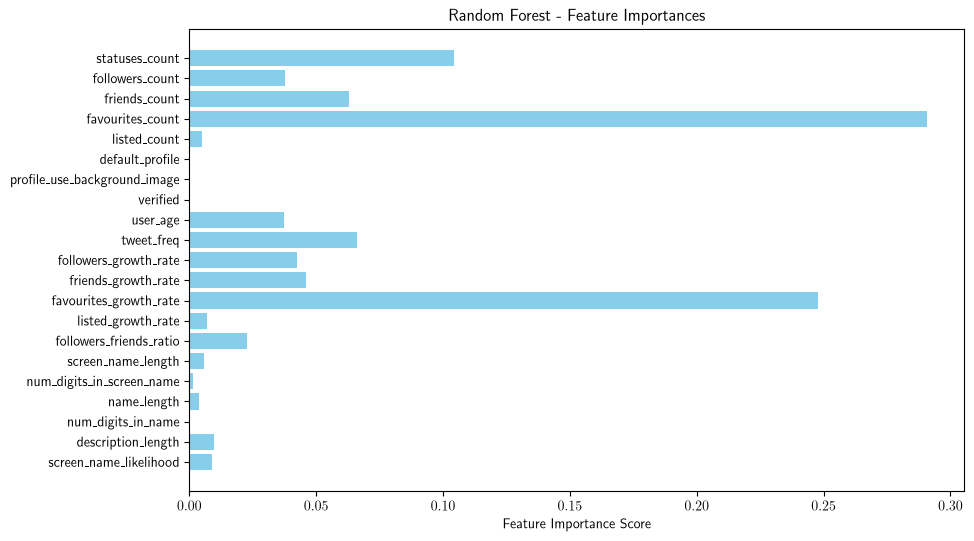

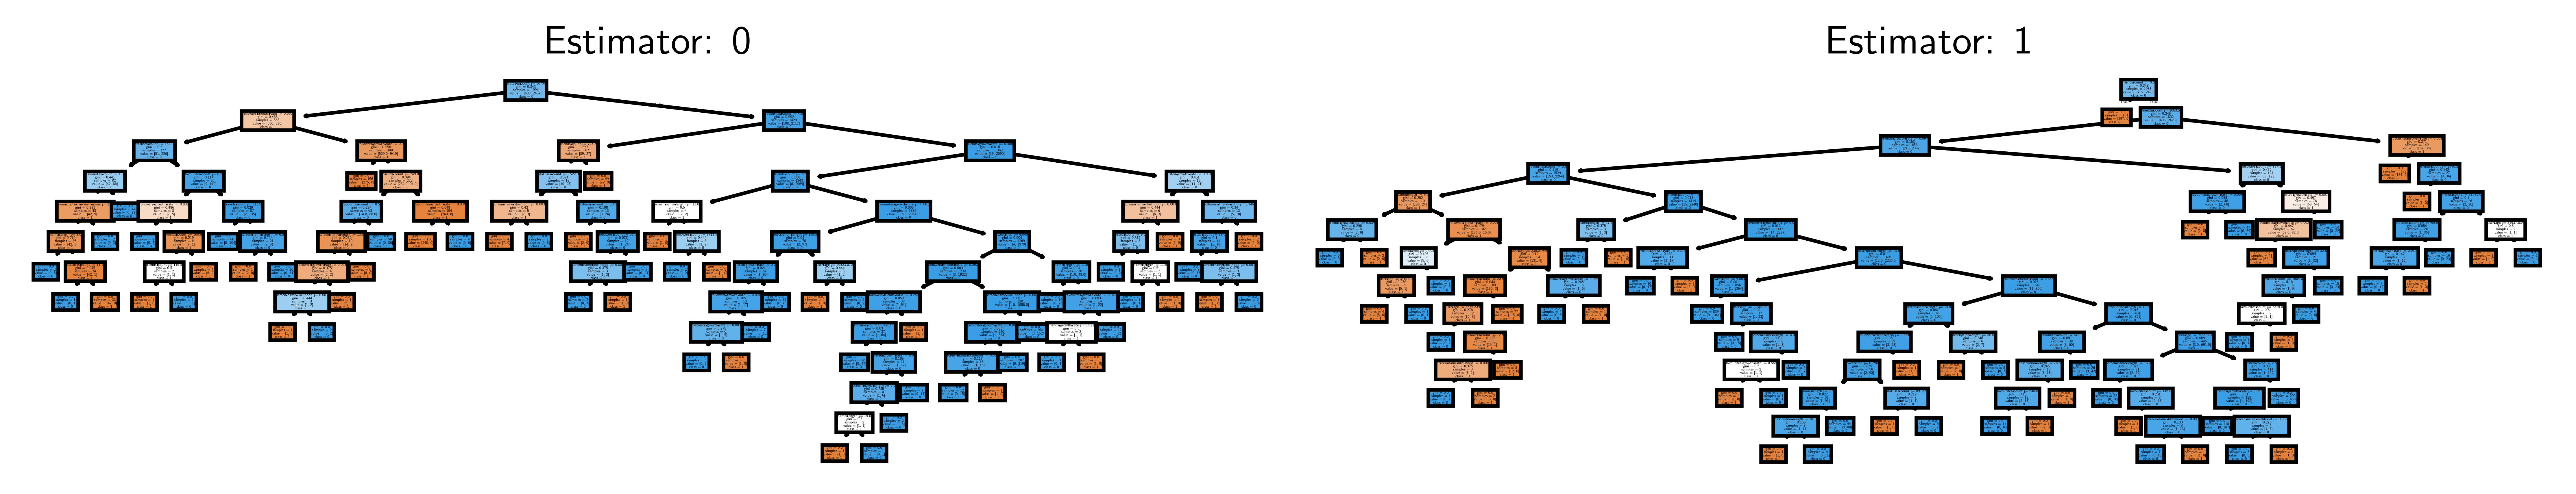

In [14]:
rfc = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rfc.fit(X_train, y_train)

# perf
y_hat = rfc.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_hat):.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_hat, target_names=target_names))

# vis
def visualize_random_forest_important_features(rfc):
    importances = rfc.feature_importances_
    plt.figure(figsize=(10, 6))
    plt.barh(list(FEATURES), importances, color='skyblue')
    plt.xlabel("Feature Importance Score")
    plt.title("Random Forest - Feature Importances")
    plt.gca().invert_yaxis() # Highest importance at the top
    plt.show()

visualize_random_forest_important_features(rfc)
plot_random_forest(rfc, first=2)


Accuracy: 0.98

Classification Report:
              precision    recall  f1-score   support

           1       0.99      0.92      0.95       287
           0       0.98      1.00      0.99      1053

    accuracy                           0.98      1340
   macro avg       0.98      0.96      0.97      1340
weighted avg       0.98      0.98      0.98      1340



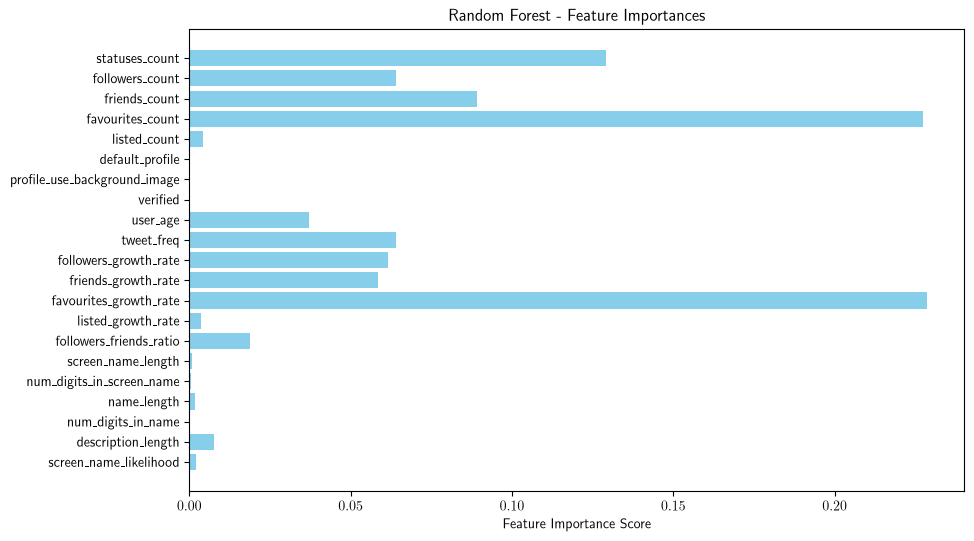

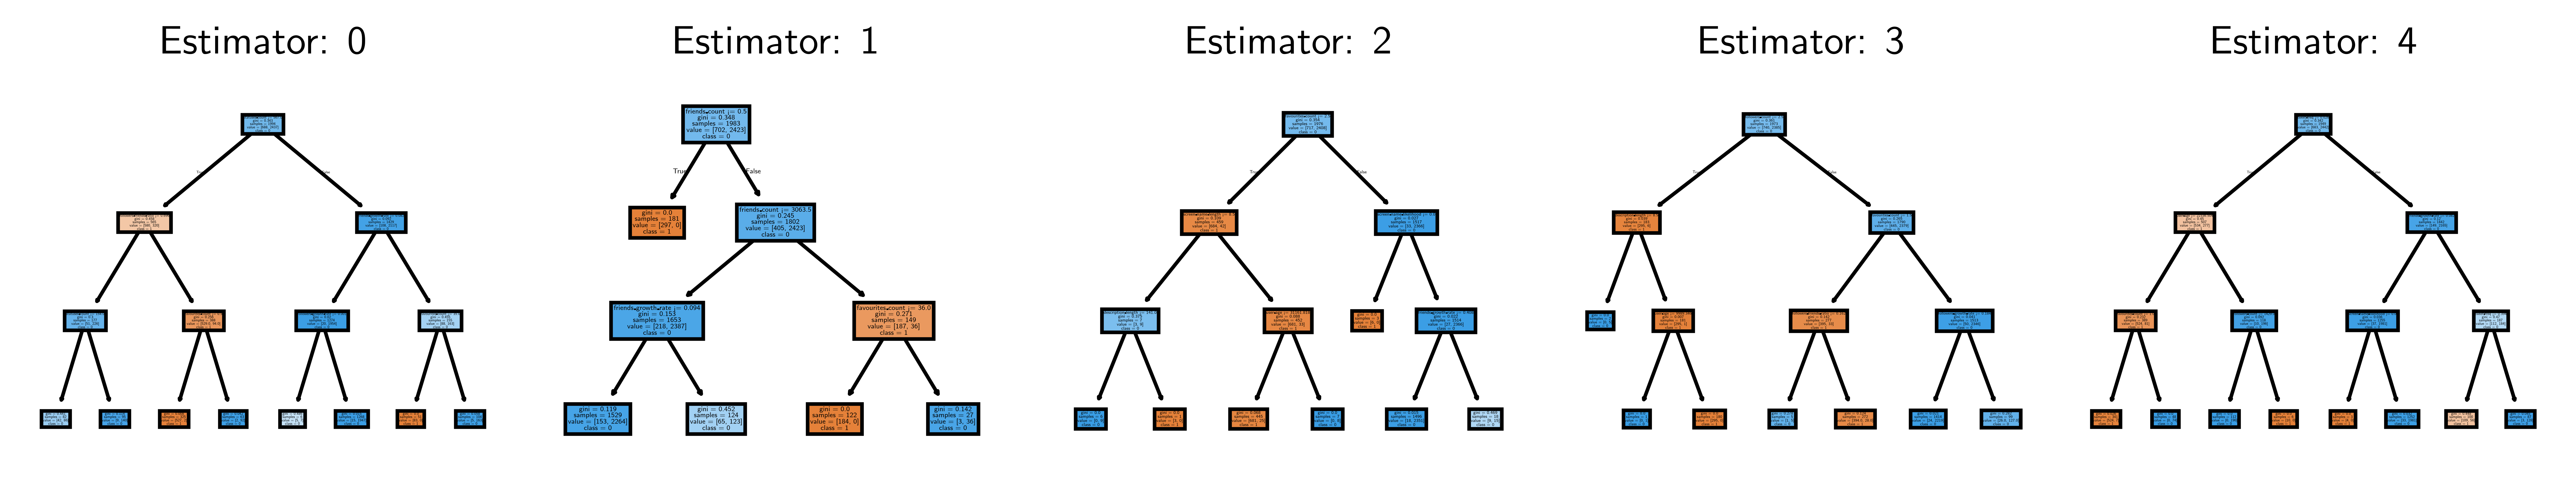

In [15]:
rfc = RandomForestClassifier(n_estimators=50, max_depth=3, random_state=RANDOM_STATE)
rfc.fit(X_train, y_train)
y_hat = rfc.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_hat):.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_hat, target_names=target_names))

visualize_random_forest_important_features(rfc)
plot_random_forest(rfc)



In [16]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=200, random_state=RANDOM_STATE)
lr.fit(X_train_scaled, y_train)
y_hat = lr.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_hat):.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_hat, target_names=target_names))

print("Model Coefficients (Weights):")
coefficients = pd.DataFrame(lr.coef_, columns=list(FEATURES), index=[target_names[1]])  # for binary classification
display(coefficients)


Accuracy: 0.92

Classification Report:
              precision    recall  f1-score   support

           1       0.85      0.74      0.79       287
           0       0.93      0.96      0.95      1053

    accuracy                           0.92      1340
   macro avg       0.89      0.85      0.87      1340
weighted avg       0.91      0.92      0.91      1340

Model Coefficients (Weights):


,statuses_count,followers_count,friends_count,favourites_count,listed_count,default_profile,profile_use_background_image,verified,user_age,tweet_freq,...,friends_growth_rate,favourites_growth_rate,listed_growth_rate,followers_friends_ratio,screen_name_length,num_digits_in_screen_name,name_length,num_digits_in_name,description_length,screen_name_likelihood
0,2.989759,0.580527,-1.785687,3.080668,3.823443,0.0,0.0,0.0,0.840846,2.604119,...,0.211584,3.82433,-2.05564,-0.096965,-0.824882,0.539142,-0.443453,0.184553,-0.059024,0.033537


In [17]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1.0, random_state=RANDOM_STATE)
svm.fit(X_train_scaled, y_train)
y_hat = svm.predict(X_test_scaled)

# 7. Evaluate the model's performance
print(f"Accuracy: {accuracy_score(y_test, y_hat):.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_hat, target_names=target_names))


Accuracy: 0.96

Classification Report:
              precision    recall  f1-score   support

           1       0.94      0.86      0.90       287
           0       0.96      0.98      0.97      1053

    accuracy                           0.96      1340
   macro avg       0.95      0.92      0.93      1340
weighted avg       0.96      0.96      0.96      1340



In [18]:
# from sklearn.tree import plot_tree

# # plot a decision tree
# plt.figure(figsize=(12, 8))
# plot_tree(
#     clf,
#     feature_names=list(FEATURES),
#     class_names=target_names,
#     filled=True,
#     rounded=True
# )
# plt.title("Decision Tree Visualization")
# plt.show()

# Appendix


## Changelog
- 2026-11-17 01:52 - done for the day, the model training works, maybe generalizes better
- 2026-11-17 01:30 - got the data cleaning and data engineering pipeline finished up, sketched out the different model types, fairly straightforward.
- 2026-11-16 11:15 - resuming
- 2026-11-16 05:07 - TODO: RESUME for some reason the bool isn't being applied so there are still nulls in there...
- 2026-11-16 03:36 - got the shape of what they did, implemented likelihood and a few other things, realized my pickle optimizations were useless because I need them as numbers, not strings, re-running.
- 2026-11-16 01:33 - all pickles processed w/ 184:26, saved 28.465% from 105.646GB to 75.574GB
- 2026-11-13 16:32 - initial commit
